# Family B - EfficientNetV2-S, run 2: resolution, label cleaning, MixUp + 5 folds

`tf_efficientnetv2_s.in21k_ft_in1k` on the team's shared clean split (Elia's `folds.csv`, 2,995 images),
evaluated on the clean and the **shifted** (test-like) validation. Study and reasons:
`families/B_effnetv2/DECISIONS.md`.

**Run 1 (30 epochs, hue + blur + photometric/translation, D4 TTA)**: OOF **0.827 clean / 0.8285 shifted**
(Elia's ConvNeXt-Tiny: 0.844 / 0.820). The test shift is handled (shifted ≈ clean); what is left is
in-distribution error:
- the validation F1 peaks at epochs 18-22 and then slowly drops -> **20 epochs**;
- hue-view TTA gained only +0.002 for 3x test time -> **removed**;
- the errors are mostly between neighbouring morphologies: tight ↔ loose spiral (85), barred ↔ loose
  (52), disturbed ↔ loose (56) and disturbed -> in-between smooth (22): fine detail (arm winding, bars);
- 128 training images (4.3%) are **confidently contradicted** by the out-of-fold models
  (p(label) < 0.05, another class > 0.7), 40 of them labelled *disturbed* (22% of that class):
  checked by eye, most are visibly mislabelled (e.g. smooth ellipticals labelled *disturbed*);
- per-class probability multipliers fitted with nested CV gained only +0.002 -> not used.

**Stage 1 (fold 0)** starts from the run-1 recipe at 20 epochs and adds, one at a time, with the team
rule (shifted F1 +≥0.01, clean −≤0.01, class 4 must not collapse):
1. **resolution 320** (upsampled; EfficientNetV2-S was pretrained at 300-384 px, spirals and bars are small);
2. **drop the 128 likely-mislabelled images from training** (validation is never filtered);
3. **MixUp 0.2** (regularisation against the late-epoch overfitting and the label noise).

**Stage 2**: the 4 other folds with the chosen recipe (fold 0 reused), D4 TTA on the test, 5-model average.

**Kaggle settings**: *Add Input* `an2dl2627-data` + `batchsize4-shared-split`; *Accelerator* **GPU T4 x2**;
*Internet* **on**. Check: `SMOKE = True` + *Run All* (~3 min). Full run: `SMOKE = False`, then
*Save Version > Save & Run All*. Outputs: `/kaggle/working/outputs/<RUN>/` and `/kaggle/working/submission.csv`.

In [1]:
import os
os.environ["AN2DL_COMMON_DIR"] = os.path.expanduser("~/an2dl_common")
os.environ["AN2DL_DATA"] = os.path.expanduser("~/ANN-DL-Challenge/data")

In [2]:
# ---- configuration ----
MODEL = 'tf_efficientnetv2_s.in21k_ft_in1k'
SMOKE = False            # True = tiny run (40 images per fold, 1 epoch): checks the pipeline only

RUN_ABLATION = True      # stage 1 on ABLATION_FOLD
ABLATION_FOLD = 0
RECIPE_FIXED = None      # e.g. dict(img_size=320) to skip stage 1 and use RECIPE_BASE updated with it
RUN_FINAL = True         # stage 2
FOLDS = [0, 1, 2, 3, 4]
PREDICT_TEST = True

EPOCHS = 20              # run 1: validation F1 peaked at epochs 18-22
BATCH_SIZE = 32
LR = 3e-4                # AdamW, 1 epoch warmup then cosine
WEIGHT_DECAY = 0.05
LABEL_SMOOTHING = 0.1
DROP_RATE, DROP_PATH_RATE = 0.2, 0.1
EMA_DECAY = 0.998
EVAL_EVERY = 2
SEED = 42
LOAD_THREADS = 32        # parallel PNG reads (I/O-bound on Kaggle)

# run-1 winner (all three augmentation steps were kept by the fold-0 study)
RECIPE_BASE = dict(
    img_size=256, mixup=0.0, drop_noisy=False,
    aug=dict(hue_p=0.5, hue_max_turn=0.5,                 # HSV hue rotation, full circle
             blur_p=0.3, blur_sigma=(0.3, 1.3),           # Gaussian blur at native 256 px
             photometric=True, brightness=(0.8, 1.15), contrast=(0.85, 1.15), sky_offset=(-0.03, 0.04),
             noise_p=0.2, noise_sigma=(0.0, 0.015),
             translate=0.04))                             # + any-angle rotation and flip, always
RECIPE_STEPS = [
    ('resolution 320', dict(img_size=320)),
    ('drop likely mislabelled training images', dict(drop_noisy=True)),
    ('MixUp 0.2', dict(mixup=0.2)),
]
# training images confidently contradicted by the run-1 out-of-fold models (p(label) < 0.05 and another
# class > 0.7; list in families/B_effnetv2/label_noise_run1.csv). Removed from TRAINING only.
NOISY_IDS = [f'train_{n:05d}' for n in [
    10, 174, 176, 190, 220, 223, 240, 299, 300, 304, 343, 347, 354, 387, 404, 471,
    555, 563, 564, 598, 601, 632, 647, 710, 712, 728, 758, 782, 797, 798, 833, 840,
    872, 956, 1003, 1032, 1062, 1093, 1124, 1125, 1143, 1159, 1163, 1199, 1271, 1274, 1282, 1302,
    1382, 1396, 1467, 1475, 1535, 1562, 1600, 1629, 1684, 1710, 1714, 1778, 1812, 1826, 1829, 1890,
    2109, 2160, 2222, 2230, 2263, 2265, 2290, 2297, 2309, 2329, 2371, 2466, 2473, 2599, 2682, 2706,
    2713, 2734, 2756, 2764, 2807, 2879, 2905, 3003, 3095, 3159, 3173, 3180, 3293, 3329, 3352, 3373,
    3375, 3385, 3401, 3428, 3517, 3585, 3588, 3622, 3626, 3654, 3679, 3685, 3772, 3779, 3799, 3813,
    3826, 3846, 3847, 3909, 3918, 3932, 3958, 4003, 4045, 4088, 4155, 4165, 4201, 4211, 4259, 4281]]
RUN = 'B_effnetv2s_run2' + ('_smoke' if SMOKE else '')

In [3]:
import glob, os, sys, time, json, random, shutil, math, gc
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

# common.py comes with Elia's dataset (batchsize4-shared-split); off Kaggle set AN2DL_COMMON_DIR
_hits = glob.glob('/kaggle/input/**/common.py', recursive=True)
COMMON_DIR = os.path.dirname(_hits[0]) if _hits else os.environ['AN2DL_COMMON_DIR']
sys.path.insert(0, COMMON_DIR)
import common as C

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm
import timm.utils
from PIL import Image

DEVICE = torch.device('cuda' if torch.cuda.is_available() else
                      'mps' if torch.backends.mps.is_available() else 'cpu')
USE_AMP = DEVICE.type == 'cuda'
# bf16 only on GPUs that have it in hardware (A100/L4); T4/P100 would emulate it slowly -> fp16
AMP_DTYPE = torch.bfloat16 if USE_AMP and torch.cuda.get_device_capability()[0] >= 8 else torch.float16
torch.backends.cudnn.benchmark = True

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

run_dir = C.OUT / RUN
run_dir.mkdir(parents=True, exist_ok=True)
T_START = time.time()
print('common.py:', COMMON_DIR)
print('DATA  =', C.DATA)
print('OUT   =', run_dir)
print('device:', DEVICE, torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else '',
      '| amp:', AMP_DTYPE if USE_AMP else 'off', '| torch', torch.__version__, '| timm', timm.__version__)

common.py: /home/elia/an2dl_common
DATA  = /home/elia/ANN-DL-Challenge/data
OUT   = /home/elia/an2dl_common/outputs/B_effnetv2s_run2
device: cuda NVIDIA GeForce RTX 5070 Ti | amp: torch.bfloat16 | torch 2.11.0+cu128 | timm 1.0.31


## Input checks

In [4]:
train_csv = pd.read_csv(C.DATA / 'train.csv')
sample_sub = pd.read_csv(C.DATA / 'sample_submission.csv')
folds = pd.read_csv(C.SPLITS / 'folds.csv')
plan = pd.read_csv(C.SPLITS / 'val_shift_plan.csv').set_index('id')
n_test_png = len(list((C.DATA / 'test').glob('*.png')))

assert len(train_csv) == 4328, len(train_csv)
assert n_test_png == 14736 and len(sample_sub) == 14736, (n_test_png, len(sample_sub))
assert list(sample_sub.columns) == ['id', 'label']
assert len(folds) == 2995 and sorted(folds.fold.unique()) == [0, 1, 2, 3, 4]
assert plan.index.tolist() == folds.id.tolist(), 'shift plan not aligned with folds.csv'
assert all((C.DATA / 'train' / f'{i}.png').exists() for i in folds.id), 'missing train images'
lab = train_csv.set_index('id').label
assert (lab[folds.id].values == folds.label.values).all(), 'labels differ from train.csv'
assert len(NOISY_IDS) == 128 and set(NOISY_IDS) <= set(folds.id), 'noisy list not in the clean set'
print('inputs OK: 4,328 train rows, 2,995 clean images in 5 folds, 14,736 test images, 128 noisy ids')
print('noisy ids per class:', folds[folds.id.isin(NOISY_IDS)].label.value_counts().sort_index().to_dict())

inputs OK: 4,328 train rows, 2,995 clean images in 5 folds, 14,736 test images, 128 noisy ids
noisy ids per class: {0: 40, 1: 10, 2: 5, 3: 3, 4: 7, 5: 9, 6: 12, 7: 31, 8: 6, 9: 5}


## Images: clean set (+ shifted copy) on the GPU, test set in RAM

In [5]:
if SMOKE:
    FOLDS, EPOCHS, BATCH_SIZE, EVAL_EVERY = FOLDS[:2], 1, 8, 1    # batch 8 fits an 8 GB Mac
    keep = folds.groupby('fold').head(40).id
    folds = folds[folds.id.isin(set(keep) | set(NOISY_IDS[:10]))].reset_index(drop=True)
    plan = plan.loc[folds.id]
te_ids = sample_sub.id.tolist()[:64] if SMOKE else sample_sub.id.tolist()

# Reading PNGs from /kaggle/input is latency-bound (run 1: 13 images/s single-threaded, 17 min of
# loading): many threads overlap the waits. Each clean image is read once; its shifted copy is built
# from it with the plan's parameters (identical to C.load_shifted, checked below).
def read_clean_and_shifted(i):
    img = C.load_image(i)
    r = plan.loc[i]
    return np.asarray(img, np.uint8), np.asarray(C.apply_shift(img, r.blur_sigma, r.hue_deg), np.uint8)

t0 = time.time()
with ThreadPoolExecutor(LOAD_THREADS) as ex:
    pairs = list(ex.map(read_clean_and_shifted, folds.id))
X_all = torch.from_numpy(np.stack([a for a, _ in pairs])).permute(0, 3, 1, 2).contiguous().to(DEVICE)
X_all_shift = torch.from_numpy(np.stack([b for _, b in pairs])).permute(0, 3, 1, 2).contiguous().to(DEVICE)
del pairs
for j in range(0, len(folds), max(1, len(folds) // 3)):        # same pixels as the team's C.load_shifted
    ref = torch.from_numpy(np.asarray(C.load_shifted(folds.id[j], plan), np.uint8)).permute(2, 0, 1)
    assert torch.equal(X_all_shift[j].cpu(), ref), folds.id[j]
y_all = folds.label.values
y_all_t = torch.as_tensor(y_all, device=DEVICE)
is_noisy = folds.id.isin(NOISY_IDS).values
print(f'clean set on {DEVICE}: {len(X_all)} images (+ shifted copy) in {time.time() - t0:.0f}s')

X_test = None
if RUN_FINAL and PREDICT_TEST:
    t0 = time.time()
    arr = np.empty((len(te_ids), 256, 256, 3), np.uint8)       # preallocated: no second 2.9 GB copy
    def read_test(j):
        arr[j] = np.asarray(Image.open(C.DATA / 'test' / f'{te_ids[j]}.png').convert('RGB'))
    with ThreadPoolExecutor(LOAD_THREADS) as ex:
        list(ex.map(read_test, range(len(te_ids))))
    X_test = torch.from_numpy(arr).permute(0, 3, 1, 2)          # uint8 view (N, 3, H, W), stays in RAM
    print(f'test set in RAM: {tuple(X_test.shape)} in {time.time() - t0:.0f}s')

/tmp/ipykernel_6238/2502807145.py:23: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at /pytorch/torch/csrc/utils/tensor_numpy.cpp:213.)
  ref = torch.from_numpy(np.asarray(C.load_shifted(folds.id[j], plan), np.uint8)).permute(2, 0, 1)


clean set on cuda: 2995 images (+ shifted copy) in 8s
test set in RAM: (14736, 3, 256, 256) in 17s


## GPU augmentation (same as run 1)

In [6]:
# float images in [0, 1], shape (B, 3, H, W), one random parameter per image
def rgb_to_hsv(x):
    r, g, b = x.unbind(1)
    maxc, minc = x.max(1)[0], x.min(1)[0]
    delta = maxc - minc
    d = delta.clamp_min(1e-8)
    h = torch.where(maxc == r, (g - b) / d, torch.where(maxc == g, 2.0 + (b - r) / d, 4.0 + (r - g) / d))
    h = torch.where(delta > 0, (h / 6.0) % 1.0, torch.zeros_like(h))
    s = torch.where(maxc > 0, delta / maxc.clamp_min(1e-8), torch.zeros_like(maxc))
    return torch.stack([h, s, maxc], 1)

def hsv_to_rgb(x):
    h, s, v = x.unbind(1)
    i = torch.floor(h * 6.0)
    f = h * 6.0 - i
    p, q, t = v * (1 - s), v * (1 - s * f), v * (1 - s * (1 - f))
    i = (i.long() % 6).unsqueeze(1)
    r = torch.stack([v, q, p, p, t, v], 1).gather(1, i)
    g = torch.stack([t, v, v, q, p, p], 1).gather(1, i)
    b = torch.stack([p, p, t, v, v, q], 1).gather(1, i)
    return torch.cat([r, g, b], 1)

def hue_rotate(x, turns):
    hsv = rgb_to_hsv(x)
    hsv[:, 0] = (hsv[:, 0] + turns.view(-1, 1, 1)) % 1.0
    return hsv_to_rgb(hsv).clamp(0, 1)

def gaussian_blur(x, sigma, ksize=9):
    B, Ch, H, W = x.shape
    half = ksize // 2
    coords = torch.arange(-half, half + 1, device=x.device, dtype=x.dtype)
    k = torch.exp(-coords.view(1, -1) ** 2 / (2 * sigma.to(x.dtype).clamp_min(1e-3).view(-1, 1) ** 2))
    k = (k / k.sum(1, keepdim=True)).repeat_interleave(Ch, 0)
    y = x.reshape(1, B * Ch, H, W)
    y = F.conv2d(F.pad(y, (half, half, 0, 0), mode='reflect'), k.view(B * Ch, 1, 1, -1), groups=B * Ch)
    y = F.conv2d(F.pad(y, (0, 0, half, half), mode='reflect'), k.view(B * Ch, 1, -1, 1), groups=B * Ch)
    return y.view(B, Ch, H, W)

def affine(x, angle, flip, tx, ty):
    # rotation by any angle, optional horizontal flip, translation (normalised units); reflection padding
    cos, sin = torch.cos(angle), torch.sin(angle)
    theta = torch.zeros(x.shape[0], 2, 3, device=x.device, dtype=x.dtype)
    theta[:, 0, 0], theta[:, 0, 1], theta[:, 0, 2] = cos * flip, -sin, tx
    theta[:, 1, 0], theta[:, 1, 1], theta[:, 1, 2] = sin * flip, cos, ty
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    return F.grid_sample(x, grid, mode='bilinear', padding_mode='reflection', align_corners=False)

def on_subset(x, mask, fn, *params):
    if mask.any():
        x = x.clone()
        x[mask] = fn(x[mask], *[p[mask] for p in params])
    return x

def augment(x, A):
    B = x.shape[0]
    u = lambda lo=0.0, hi=1.0: (torch.rand(B, generator=GEN) * (hi - lo) + lo).to(x.device)
    if A['hue_p'] > 0:
        x = on_subset(x, u() < A['hue_p'], hue_rotate, u(-A['hue_max_turn'], A['hue_max_turn']))
    if A['blur_p'] > 0:
        x = on_subset(x, u() < A['blur_p'], gaussian_blur, u(*A['blur_sigma']))
    if A['photometric']:
        b, c, o = u(*A['brightness']), u(*A['contrast']), u(*A['sky_offset'])
        mean = x.mean(dim=(1, 2, 3), keepdim=True)
        x = ((x - mean) * c.view(-1, 1, 1, 1) + mean) * b.view(-1, 1, 1, 1) + o.view(-1, 1, 1, 1)
        sigma = (u() < A['noise_p']).float() * u(*A['noise_sigma'])
        x = (x + torch.randn_like(x) * sigma.view(-1, 1, 1, 1)).clamp(0, 1)
    flip = torch.where(u() < 0.5, -1.0, 1.0)
    t = 2 * A['translate']                                  # fraction of the side -> normalised units
    return affine(x, u(0, 2 * math.pi), flip, u(-t, t), u(-t, t))


def prepare(x_uint8, size, A=None):
    # uint8 batch (any device) -> normalised float on the GPU at `size` px; augmented (at native 256) if A
    x = x_uint8.to(DEVICE, non_blocking=True).float().div_(255)
    if A is not None:
        x = augment(x, A)
    if size != x.shape[-1]:
        x = F.interpolate(x, size=(size, size), mode='bilinear', antialias=True, align_corners=False)
    return ((x - MEAN_T) / STD_T).contiguous(memory_format=torch.channels_last)

## Model, training, evaluation

In [7]:
_cfg = timm.create_model(MODEL, pretrained=False).pretrained_cfg
MEAN_T = torch.tensor(_cfg['mean'], device=DEVICE).view(1, 3, 1, 1)
STD_T = torch.tensor(_cfg['std'], device=DEVICE).view(1, 3, 1, 1)

def make_model(pretrained=True):
    net = timm.create_model(MODEL, pretrained=pretrained, num_classes=C.N_CLASSES,
                            drop_rate=DROP_RATE, drop_path_rate=DROP_PATH_RATE)
    head = net.get_classifier()          # zero-init the new head: starts at uniform predictions
    nn.init.zeros_(head.weight); nn.init.zeros_(head.bias)
    return net.to(DEVICE).to(memory_format=torch.channels_last)

@torch.no_grad()
def predict(net, X, size, d4=False, bs=None):
    # logits (N, 10) for a uint8 tensor (GPU or CPU); d4 = mean over 4 rotations x 2 flips
    net.eval()
    bs = bs or 2 * BATCH_SIZE
    out = []
    for s in range(0, len(X), bs):
        x = prepare(X[s:s + bs], size)
        views = [torch.rot90(v, k, (2, 3)) for v in ([x, x.flip(3)] if d4 else [x]) for k in (range(4) if d4 else [0])]
        acc = 0
        for v in views:
            with torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                acc = acc + net(v).float()
        out.append((acc / len(views)).cpu())
    return torch.cat(out).numpy()

def scores(y, logits_clean, logits_shift):
    rc, rs = C.evaluate(y, logits_clean.argmax(1)), C.evaluate(y, logits_shift.argmax(1))
    return {'f1_clean': round(float(rc['f1_weighted']), 4), 'f1_shifted': round(float(rs['f1_weighted']), 4),
            'f1_cigar_clean': round(float(rc['f1_per_class'].iloc[4]), 4),
            'f1_cigar_shifted': round(float(rs['f1_per_class'].iloc[4]), 4)}

def log(row):
    print(' '.join(f'{k}={v:.4g}' if isinstance(v, float) else f'{k}={v}' for k, v in row.items()), flush=True)

def fit(k, R, tag):
    # trains on folds != k with recipe R, evaluates fold k with D4 TTA, saves everything.
    # If tag was already trained in this session, reloads it. Returns (eval model, metrics).
    if (run_dir / f'{tag}_metrics.json').exists():
        net = make_model(pretrained=False)
        net.load_state_dict(torch.load(run_dir / f'{tag}_ema.pt', map_location=DEVICE))
        print(f'[{tag}] already trained, reloaded')
        return net, json.load(open(run_dir / f'{tag}_metrics.json'))
    seed_everything(SEED + k)
    global GEN
    GEN = torch.Generator().manual_seed(SEED * 100 + k)     # augmentation draws: reproducible per fold
    mix_rng = np.random.default_rng(SEED * 100 + k)
    size, A = R['img_size'], R['aug']
    train_mask = folds.fold.values != k
    if R['drop_noisy']:
        train_mask &= ~is_noisy                              # training only: validation is never filtered
    tr = np.where(train_mask)[0]
    va = np.where(folds.fold.values == k)[0]
    tr_t = torch.as_tensor(tr, device=DEVICE)
    print(f'\n===== [{tag}] fold {k}: train {len(tr)} | val {len(va)} | {size}px | mixup {R["mixup"]} '
          f'| drop_noisy {R["drop_noisy"]} =====', flush=True)

    model = make_model()
    steps_per_epoch = len(tr) // BATCH_SIZE
    steps = EPOCHS * steps_per_epoch
    warmup = min(steps_per_epoch, steps // 10 + 1)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, lambda s: (s + 1) / warmup if s < warmup else
        0.01 + 0.99 * 0.5 * (1 + np.cos(np.pi * (s - warmup) / max(1, steps - warmup))))
    criterion = nn.CrossEntropyLoss(label_smoothing=LABEL_SMOOTHING)   # accepts soft (MixUp) targets
    scaler = torch.amp.GradScaler('cuda', enabled=USE_AMP and AMP_DTYPE == torch.float16)
    if hasattr(timm.utils, 'ModelEmaV3'):   # warmup: the average does not drag the random-head start along
        ema, ema_warmup = timm.utils.ModelEmaV3(model, decay=EMA_DECAY, use_warmup=True), True
    else:
        ema, ema_warmup = timm.utils.ModelEmaV2(model, decay=EMA_DECAY), False

    history, t0, step = [], time.time(), 0
    for epoch in range(1, EPOCHS + 1):
        model.train()
        te, tot, n = time.time(), 0.0, 0
        perm = tr_t[torch.randperm(len(tr), generator=GEN).to(DEVICE)]
        for s in range(steps_per_epoch):
            idx = perm[s * BATCH_SIZE:(s + 1) * BATCH_SIZE]
            x, y = prepare(X_all[idx], size, A=A), y_all_t[idx]
            target = y
            if R['mixup'] > 0:                                  # MixUp: blend pairs of images and their labels
                lam = float(mix_rng.beta(R['mixup'], R['mixup']))
                pair = torch.randperm(len(y), generator=GEN).to(DEVICE)
                x = lam * x + (1 - lam) * x[pair]
                oh = F.one_hot(y, C.N_CLASSES).float()
                target = lam * oh + (1 - lam) * oh[pair]
            with torch.autocast(DEVICE.type, dtype=AMP_DTYPE, enabled=USE_AMP):
                loss = criterion(model(x), target)
            optimizer.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            scaler.step(optimizer); scaler.update(); scheduler.step()
            step += 1
            ema.update(model, step=step) if ema_warmup else ema.update(model)
            tot += loss.item() * len(y); n += len(y)
        row = {'tag': tag, 'epoch': epoch, 'train_loss': round(tot / n, 4),
               'lr': optimizer.param_groups[0]['lr'], 'sec': round(time.time() - te, 1)}
        if epoch % EVAL_EVERY == 0 or epoch == EPOCHS:
            lc, ls = predict(ema.module, X_all[va], size), predict(ema.module, X_all_shift[va], size)
            row.update(val_loss=round(F.cross_entropy(torch.from_numpy(lc), torch.from_numpy(y_all[va])).item(), 4),
                       **{kk: v for kk, v in scores(y_all[va], lc, ls).items() if kk in ('f1_clean', 'f1_shifted')})
        history.append(row); log(row)

    net = ema.module
    del model, optimizer, ema
    clean, shift = predict(net, X_all[va], size, d4=True), predict(net, X_all_shift[va], size, d4=True)
    np.savez(run_dir / f'{tag}_val.npz', idx=va, clean=clean.astype(np.float32), shifted=shift.astype(np.float32))
    pd.DataFrame(history).to_csv(run_dir / f'{tag}_history.csv', index=False)
    torch.save(net.state_dict(), run_dir / f'{tag}_ema.pt')
    metrics = {'tag': tag, 'fold': k, **scores(y_all[va], clean, shift),
               'minutes': round((time.time() - t0) / 60, 1), 'n_train': int(len(tr)), 'recipe': R}
    json.dump(metrics, open(run_dir / f'{tag}_metrics.json', 'w'), indent=2)
    print(f'[{tag}] D4 TTA: f1_clean={metrics["f1_clean"]} f1_shifted={metrics["f1_shifted"]} '
          f'cigar {metrics["f1_cigar_clean"]}/{metrics["f1_cigar_shifted"]} | {metrics["minutes"]} min', flush=True)
    return net, metrics

def free():
    # call after `del net`: releases the GPU memory of models no longer referenced
    gc.collect()
    if DEVICE.type == 'cuda':
        torch.cuda.empty_cache()

def with_change(R, change):
    R2 = json.loads(json.dumps(R))          # deep copy
    R2.update(change)
    return R2

## Stage 1 - recipe study (fold 0)

Greedy, one change at a time, team rule: shifted F1 +≥0.01, clean −≤0.01, class 4 must not collapse.
Single-fold differences below ~0.01 are noise: then the simpler recipe wins.

In [8]:
ablation, WINNER_TAG = [], None
cols = ('f1_clean', 'f1_shifted', 'f1_cigar_clean', 'f1_cigar_shifted', 'minutes')
if RECIPE_FIXED is not None:
    RECIPE = with_change(RECIPE_BASE, RECIPE_FIXED)
    print('stage 1 skipped, fixed recipe:', RECIPE)
elif RUN_ABLATION:
    current = with_change(RECIPE_BASE, {})
    net, best = fit(ABLATION_FOLD, current, 'abl0'); del net; free()
    best_tag = 'abl0'
    ablation.append({'step': 'control (run-1 recipe, 20 epochs)', **{c: best[c] for c in cols}, 'kept': True})
    for i, (name, change) in enumerate(RECIPE_STEPS, 1):
        cand = with_change(current, change)
        net, m = fit(ABLATION_FOLD, cand, f'abl{i}'); del net; free()
        d_clean, d_shift = m['f1_clean'] - best['f1_clean'], m['f1_shifted'] - best['f1_shifted']
        collapse = m['f1_cigar_shifted'] < 0.5 * best['f1_cigar_shifted']
        kept = d_shift >= 0.01 and d_clean >= -0.01 and not collapse
        print(f'\n>>> step "{name}": {"KEPT" if kept else "rejected"} - shifted {d_shift:+.4f} (needs >= +0.01), '
              f'clean {d_clean:+.4f} (needs >= -0.01){", class 4 collapsed" if collapse else ""}\n', flush=True)
        ablation.append({'step': f'+ {name}', **{c: m[c] for c in cols}, 'kept': kept})
        if kept:
            current, best, best_tag = cand, m, f'abl{i}'
    RECIPE, WINNER_TAG = current, best_tag
else:
    RECIPE = with_change(RECIPE_BASE, {})
    print('stage 1 skipped, run-1 recipe:', RECIPE)

if ablation:
    abl = pd.DataFrame(ablation)
    abl.to_csv(run_dir / 'ablation.csv', index=False)
    print(abl.to_string(index=False))
    if SMOKE:
        print('(SMOKE: these numbers mean nothing, the run only checks the pipeline)')
json.dump(RECIPE, open(run_dir / 'recipe_selected.json', 'w'), indent=2)
print('\nchosen recipe:', {k: v for k, v in RECIPE.items() if k != 'aug'}, '| from', WINNER_TAG)
print(f'elapsed so far: {(time.time() - T_START) / 60:.0f} min')


===== [abl0] fold 0: train 2396 | val 599 | 256px | mixup 0.0 | drop_noisy False =====


tag=abl0 epoch=1 train_loss=2.043 lr=0.0003 sec=46.6
tag=abl0 epoch=2 train_loss=1.472 lr=0.000298 sec=7.5 val_loss=0.9945 f1_clean=0.6409 f1_shifted=0.6258
tag=abl0 epoch=3 train_loss=1.283 lr=0.000292 sec=7.2
tag=abl0 epoch=4 train_loss=1.183 lr=0.0002821 sec=7.3 val_loss=0.6868 f1_clean=0.7766 f1_shifted=0.7764
tag=abl0 epoch=5 train_loss=1.127 lr=0.0002687 sec=7.3
tag=abl0 epoch=6 train_loss=1.089 lr=0.0002521 sec=7.1 val_loss=0.6321 f1_clean=0.7923 f1_shifted=0.7866
tag=abl0 epoch=7 train_loss=1.032 lr=0.0002327 sec=7.1
tag=abl0 epoch=8 train_loss=0.983 lr=0.0002112 sec=7.4 val_loss=0.5985 f1_clean=0.8086 f1_shifted=0.8051
tag=abl0 epoch=9 train_loss=0.9496 lr=0.000188 sec=7
tag=abl0 epoch=10 train_loss=0.9364 lr=0.0001638 sec=7.1 val_loss=0.5621 f1_clean=0.8181 f1_shifted=0.8187
tag=abl0 epoch=11 train_loss=0.8906 lr=0.0001392 sec=7.3
tag=abl0 epoch=12 train_loss=0.8724 lr=0.000115 sec=7.2 val_loss=0.559 f1_clean=0.8139 f1_shifted=0.8276
tag=abl0 epoch=13 train_loss=0.8194 lr=9.1

## Stage 2 - all folds with the chosen recipe

Fold 0 reuses the winning model of stage 1 (same data, seed and recipe).

In [9]:
fold_metrics, final_tags = [], {}
if RUN_FINAL:
    for k in FOLDS:
        tag = WINNER_TAG if (k == ABLATION_FOLD and WINNER_TAG) else f'fold{k}'
        net, m = fit(k, RECIPE, tag)
        final_tags[k] = tag
        fold_metrics.append(m)
        tpath = run_dir / f'{tag}_test.npy'
        if PREDICT_TEST and not tpath.exists():
            tt = time.time()
            np.save(tpath, predict(net, X_test, RECIPE['img_size'], d4=True).astype(np.float32))
            print(f'[{tag}] test predicted (D4) in {(time.time() - tt) / 60:.1f} min', flush=True)
        del net; free()
    print(pd.DataFrame(fold_metrics)[['tag', 'fold', 'n_train', 'f1_clean', 'f1_shifted', 'f1_cigar_clean', 'f1_cigar_shifted', 'minutes']].to_string(index=False))
    print(f'\nelapsed so far: {(time.time() - T_START) / 60:.0f} min')

[abl1] already trained, reloaded
[abl1] test predicted (D4) in 2.2 min

===== [fold1] fold 1: train 2396 | val 599 | 320px | mixup 0.0 | drop_noisy False =====
tag=fold1 epoch=1 train_loss=2.053 lr=0.0003 sec=8.8
tag=fold1 epoch=2 train_loss=1.45 lr=0.000298 sec=8.8 val_loss=0.9357 f1_clean=0.6546 f1_shifted=0.6456
tag=fold1 epoch=3 train_loss=1.287 lr=0.000292 sec=8.7
tag=fold1 epoch=4 train_loss=1.211 lr=0.0002821 sec=8.7 val_loss=0.7469 f1_clean=0.7406 f1_shifted=0.7351
tag=fold1 epoch=5 train_loss=1.142 lr=0.0002687 sec=8.8
tag=fold1 epoch=6 train_loss=1.092 lr=0.0002521 sec=7.9 val_loss=0.6451 f1_clean=0.7737 f1_shifted=0.7699
tag=fold1 epoch=7 train_loss=1.047 lr=0.0002327 sec=8.3
tag=fold1 epoch=8 train_loss=0.9988 lr=0.0002112 sec=8.3 val_loss=0.5921 f1_clean=0.7954 f1_shifted=0.7874
tag=fold1 epoch=9 train_loss=0.9631 lr=0.000188 sec=8.7
tag=fold1 epoch=10 train_loss=0.9194 lr=0.0001638 sec=8.6 val_loss=0.5816 f1_clean=0.8001 f1_shifted=0.8104
tag=fold1 epoch=11 train_loss=0.8

## OOF scores, submission, team files

In [10]:
def softmax(z):
    z = z - z.max(-1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(-1, keepdims=True)

if RUN_FINAL and fold_metrics:
    oof_c = np.full((len(folds), C.N_CLASSES), np.nan, np.float32)
    oof_s = oof_c.copy()
    for k, tag in final_tags.items():
        d = np.load(run_dir / f'{tag}_val.npz')
        oof_c[d['idx']], oof_s[d['idx']] = softmax(d['clean']), softmax(d['shifted'])
    have = ~np.isnan(oof_c[:, 0])
    res = scores(y_all[have], oof_c[have], oof_s[have])
    print(f'OOF over folds {sorted(final_tags)} (D4 TTA):', res)
    print('reference: run 1 OOF 0.827 clean / 0.8285 shifted | Elia ConvNeXt-T 0.844 / 0.820')
    rc = C.evaluate(y_all[have], oof_c[have].argmax(1))
    rs = C.evaluate(y_all[have], oof_s[have].argmax(1))
    print('\nper-class F1 (OOF):')
    print(pd.DataFrame({'clean': rc['f1_per_class'], 'shifted': rs['f1_per_class']}).round(3).to_string())
    print('\nconfusion matrix (OOF clean, rows = true):\n', rc['confusion'])

    oof = pd.DataFrame({'id': folds.id, 'label': y_all, 'fold': folds.fold})      # Elia's format
    for nm, P in [('clean', oof_c), ('shifted', oof_s)]:
        for c in range(C.N_CLASSES):
            oof[f'p{c}_{nm}'] = P[:, c]
    oof.to_csv(run_dir / 'oof.csv', index=False)

    if PREDICT_TEST:
        P = np.stack([softmax(np.load(run_dir / f'{final_tags[k]}_test.npy')) for k in sorted(final_tags)])   # (K, N, 10)
        np.save(run_dir / 'test_probs.npy', P.astype(np.float32))
        sub = sample_sub.iloc[:len(te_ids)].copy()
        assert sub.id.tolist() == te_ids
        sub['label'] = P.mean(0).argmax(1)
        sub.to_csv(run_dir / f'submission_{RUN}.csv', index=False)
        if Path('/kaggle/working').exists() and not SMOKE:
            shutil.copy(run_dir / f'submission_{RUN}.csv', '/kaggle/working/submission.csv')
        print('\ntest class shares (%):', (100 * np.bincount(sub.label, minlength=10) / len(sub)).round(1).tolist())

    now = pd.Timestamp.now().strftime('%Y-%m-%d %H:%M')
    base = {'date': now, 'train_set': 'clean (keep=True)', 'kaggle': None}
    rows = [{**base, 'fold': ABLATION_FOLD, 'experiment': f'{RUN}_ablation',
             'note': f"{a['step']} ({'kept' if a['kept'] else 'rejected'})", **{c: a[c] for c in cols}} for a in ablation]
    rows += [{**base, 'fold': m['fold'], 'experiment': RUN, 'note': 'D4 TTA, chosen recipe',
              **{c: m[c] for c in cols}} for m in fold_metrics]
    rows += [{**base, 'fold': 'OOF', 'experiment': RUN, 'note': 'OOF, D4 TTA (submission.csv)', **res}]
    pd.DataFrame(rows).to_csv(run_dir / 'experiments_log.csv', index=False)
    json.dump({'run': RUN, 'model': MODEL, 'recipe': RECIPE, 'folds': sorted(final_tags), 'oof': res,
               'epochs': EPOCHS, 'lr': LR, 'batch_size': BATCH_SIZE, 'seed': SEED,
               'minutes_total': round((time.time() - T_START) / 60, 1),
               'device': torch.cuda.get_device_name(0) if DEVICE.type == 'cuda' else DEVICE.type},
              open(run_dir / f'{RUN}.json', 'w'), indent=2)
print(f'\ntotal time: {(time.time() - T_START) / 60:.0f} min | outputs in {run_dir}')

OOF over folds [0, 1, 2, 3, 4] (D4 TTA): {'f1_clean': 0.8401, 'f1_shifted': 0.8365, 'f1_cigar_clean': 0.8108, 'f1_cigar_shifted': 0.8257}
reference: run 1 OOF 0.827 clean / 0.8285 shifted | Elia ConvNeXt-T 0.844 / 0.820

per-class F1 (OOF):
                     clean  shifted
0 disturbed          0.505    0.487
1 merging            0.898    0.889
2 round smooth       0.915    0.921
3 in-between smooth  0.927    0.925
4 cigar              0.811    0.826
5 barred spiral      0.841    0.835
6 tight spiral       0.776    0.783
7 loose spiral       0.736    0.727
8 edge-on no bulge   0.919    0.916
9 edge-on bulge      0.928    0.919

confusion matrix (OOF clean, rows = true):
 [[ 77   6  15  19   6  14   2  34   1   8]
 [  6 282   6   4   0   3   0  11   1   0]
 [  3   5 417   0   0   4  13   4   0   0]
 [  1   4   1 326   0   1   4   6   0   0]
 [  0   0   0   3  45   1   0   0   2   5]
 [  5   7   3   2   0 298   9  19   1   2]
 [  1   1  17   5   1   9 243  30   1   1]
 [ 26  10   5   1

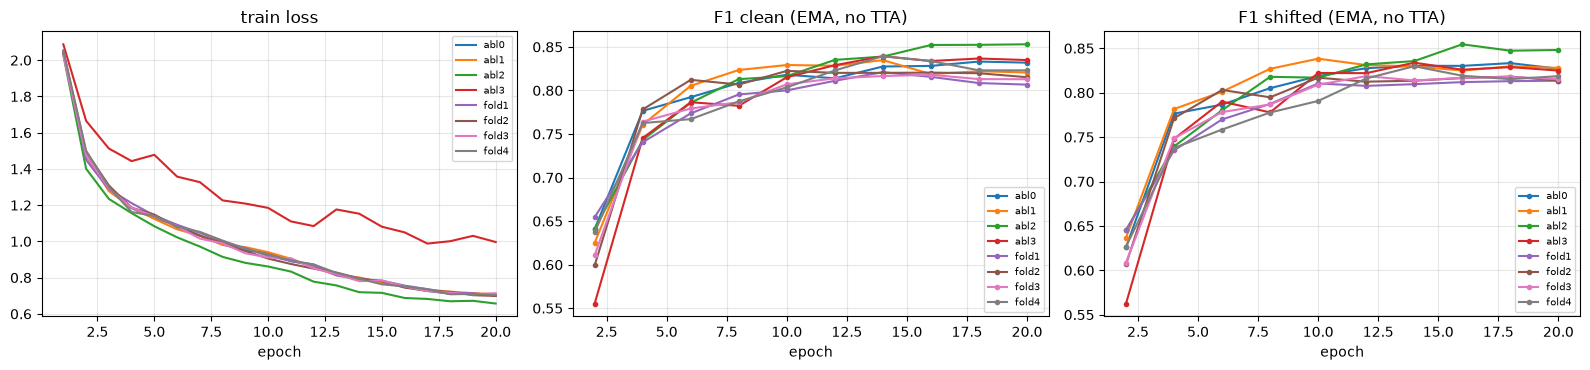

In [11]:
import matplotlib.pyplot as plt
hist = [pd.read_csv(p) for p in sorted(run_dir.glob('*_history.csv'))]
if hist:
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
    for h in hist:
        tag = h.tag.iloc[0]
        ax[0].plot(h.epoch, h.train_loss, label=tag)
        e = h.dropna(subset=['f1_clean']) if 'f1_clean' in h else h.iloc[:0]
        ax[1].plot(e.epoch, e.f1_clean, 'o-', ms=3, label=tag)
        ax[2].plot(e.epoch, e.f1_shifted, 'o-', ms=3, label=tag)
    for a, t in zip(ax, ['train loss', 'F1 clean (EMA, no TTA)', 'F1 shifted (EMA, no TTA)']):
        a.set_title(t); a.set_xlabel('epoch'); a.grid(alpha=0.3); a.legend(fontsize=7)
    plt.tight_layout(); plt.show()